# GAMMA: inspect the data and test an aggregate response baseline

**Question:** Does a transparent, inexpensive workload-to-mean-response curve predict held-out observations well enough to motivate the graph-aware model?

This notebook uses actual GAMMA compose requests, call graph 1, at **200, 400 and 800 offered RPS**. The displayed graph is an RPC/span dependency graph—not 30 identified queues. Root spans measure response time; inclusive child spans are not intrinsic service demands.

The notebook executes a short deterministic fit only. The graph-aware queueing likelihood and long inference are not run. The compact derived CSVs are committed beside this notebook; source hashes and regeneration commands appear at the end.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "hierarch_inf").is_dir())
sys.path.insert(0, str(ROOT))
from examples.queueing.gamma_baseline import fit_affine, predict_affine
DATA = ROOT / "examples/queueing/gamma/notebook_data"
PILOT = ROOT / "examples/queueing/gamma/pilot"
PREVIEW = ROOT / "examples/queueing/gamma/preview"
PREVIEW.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
colors = {200: "#277da8", 400: "#ce7d18", 800: "#8d4b99"}
def records(path):
    with open(path) as f: return list(csv.DictReader(f))
def finish(name):
    plt.tight_layout()
    plt.savefig(PREVIEW / (name + ".png"), dpi=110, bbox_inches="tight")
    plt.show()
    plt.close()
def table(headers, rows):
    display(Markdown("|"+"|".join(headers)+"|\n|"+"|".join(["---"]*len(headers))+"|\n"+
                     "\n".join("|"+"|".join(map(str,r))+"|" for r in rows)))
graphs = json.loads((DATA / "graphs.json").read_text())
provenance = json.loads((DATA / "baseline_provenance.json").read_text())
windows = records(PILOT / "windows.csv")
r = records(DATA / "baseline_windows.csv")
x = np.array([float(z["offered_rps"]) for z in r])
y = np.array([float(z["mean_response_seconds"]) for z in r])
w = np.array([float(z["requests"]) for z in r])
t = np.array([float(z["relative_start_seconds"]) + 5 for z in r])
split = np.array([z["split"] for z in r])
train = split == "train"
table(["Offered RPS", "Observed run requests", "Child-start-before-root rows", "Fit-window requests"],
      [(int(load), a["quality"]["request_rows"], a["quality"]["rows_with_child_start_before_root"],
        int(w[x==load].sum())) for load,a in zip([200,400,800],provenance["runs"])])
print("Fit input:", len(r), "nonempty ten-second windows of 72 possible;", int(w.sum()), "captured requests.")
table(["RPS", "Nonempty / 24 windows", "Empty selected-graph windows", "Edge-crossing requests excluded"],
      [(load,a["nonempty_windows"],a["empty_windows"],a["edge_crossing_requests"]) for load,a in zip([200,400,800],provenance["runs"])])

Fit input: 54 nonempty ten-second windows of 72 possible; 11180 captured requests.


|Offered RPS|Observed run requests|Child-start-before-root rows|Fit-window requests|
|---|---|---|---|
|200|15279|1849|2589|
|400|23529|17|2378|
|800|47736|30682|6213|

|RPS|Nonempty / 24 windows|Empty selected-graph windows|Edge-crossing requests excluded|
|---|---|---|---|
|200|24|0|3|
|400|13|11|2|
|800|17|7|14|

## 1. The observed RPC graph

The three selected runs have the same graph. IDs identify span positions; repeated service names are retained. Arrows indicate exported parent/child dependencies, not inferred queue routing probabilities or scheduling.

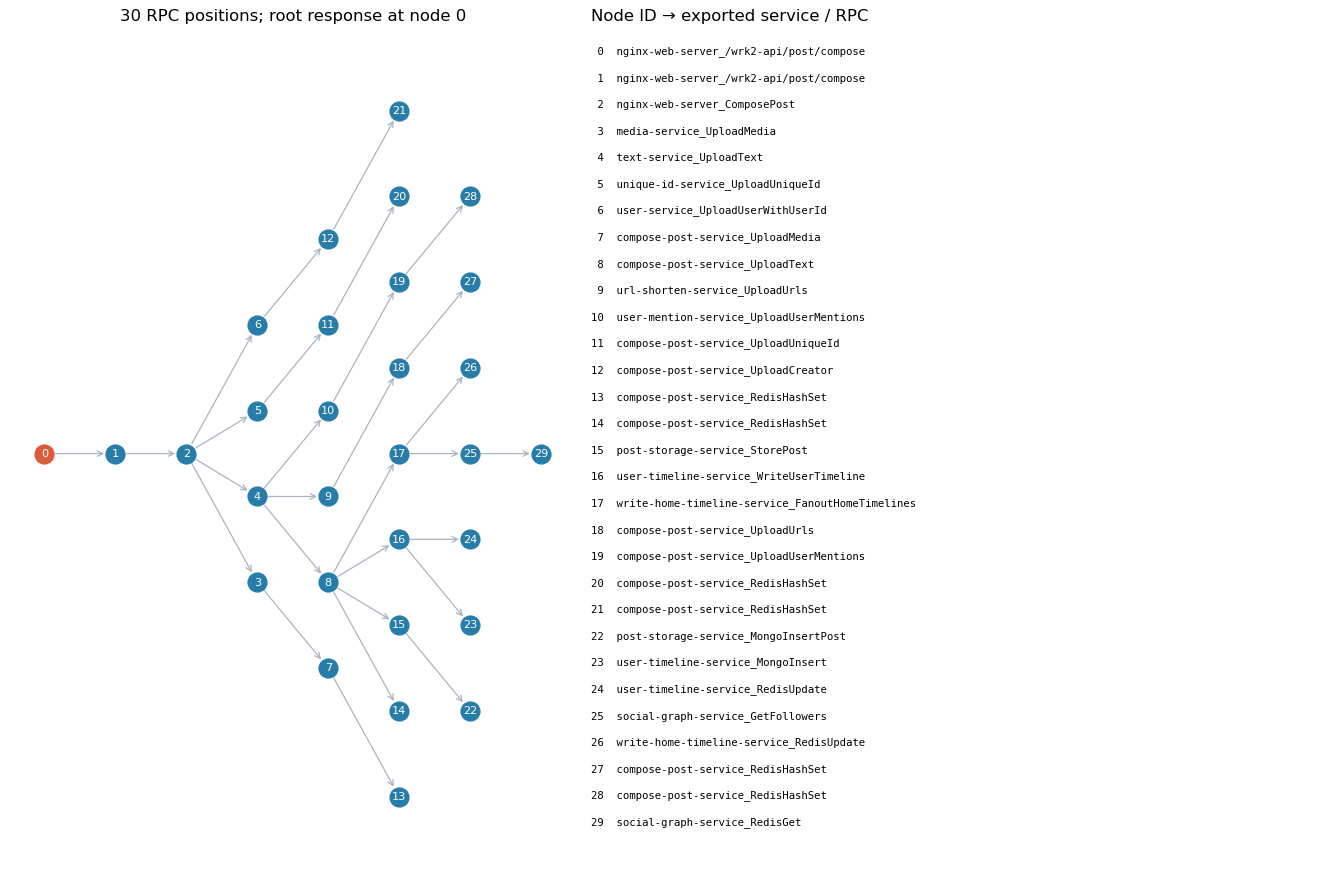

In [2]:
g = graphs[0]
assert all(z["nodes"] == g["nodes"] and z["edges"] == g["edges"] for z in graphs)
nodes = {int(k): v for k,v in g["nodes"].items()}
edges = g["edges"]
depth = {0: 0}
for _ in nodes:
    for a,b in edges:
        if a in depth: depth[b] = max(depth.get(b, 0), depth[a]+1)
levels = {d: sorted(k for k in nodes if depth[k]==d) for d in sorted(set(depth.values()))}
pos = {k: (d, j-(len(ks)-1)/2) for d,ks in levels.items() for j,k in enumerate(ks)}
fig, (ax, labels_ax) = plt.subplots(1,2, figsize=(15,10), gridspec_kw={"width_ratios":[1,1.3]})
for a,b in edges:
    ax.annotate("", xy=pos[b], xytext=pos[a], arrowprops=dict(arrowstyle="->", color="#aab4bf", lw=1, shrinkA=9, shrinkB=9), zorder=1)
for k,(xx,yy) in pos.items():
    ax.scatter(xx, yy, s=230, color="#277da8" if k else "#db5c3b", zorder=2)
    ax.text(xx,yy,str(k),ha="center",va="center",color="white",fontsize=9,zorder=3)
ax.set_title("30 RPC positions; root response at node 0")
ax.set_xlim(-.5,max(depth.values())+.5); ax.margins(y=.12); ax.axis("off")
labels_ax.axis("off")
labels_ax.set_title("Node ID → exported service / RPC",loc="left")
for i,k in enumerate(sorted(nodes)):
    labels_ax.text(0, 0.97-i/32, f"{k:2d}  {nodes[k]}", fontsize=8.5, family="monospace", transform=labels_ax.transAxes)
finish("01_rpc_graph")

## 2. Workload, time and operating regime

Each panel shows the complete exported run, relative to its first injection. Gray points are logged interference; orange points are guarded/mixed transition windows. Blue points are outside logged injections. The logarithmic response axis retains rare long-response windows without flattening typical values. The pale blue interval is the **same 240-second pre-injection interval** used for baseline fitting/evaluation, ending five seconds before injection. Counts are graph-specific captured requests, not total offered RPS. Warm-up completion is not established by the exports.

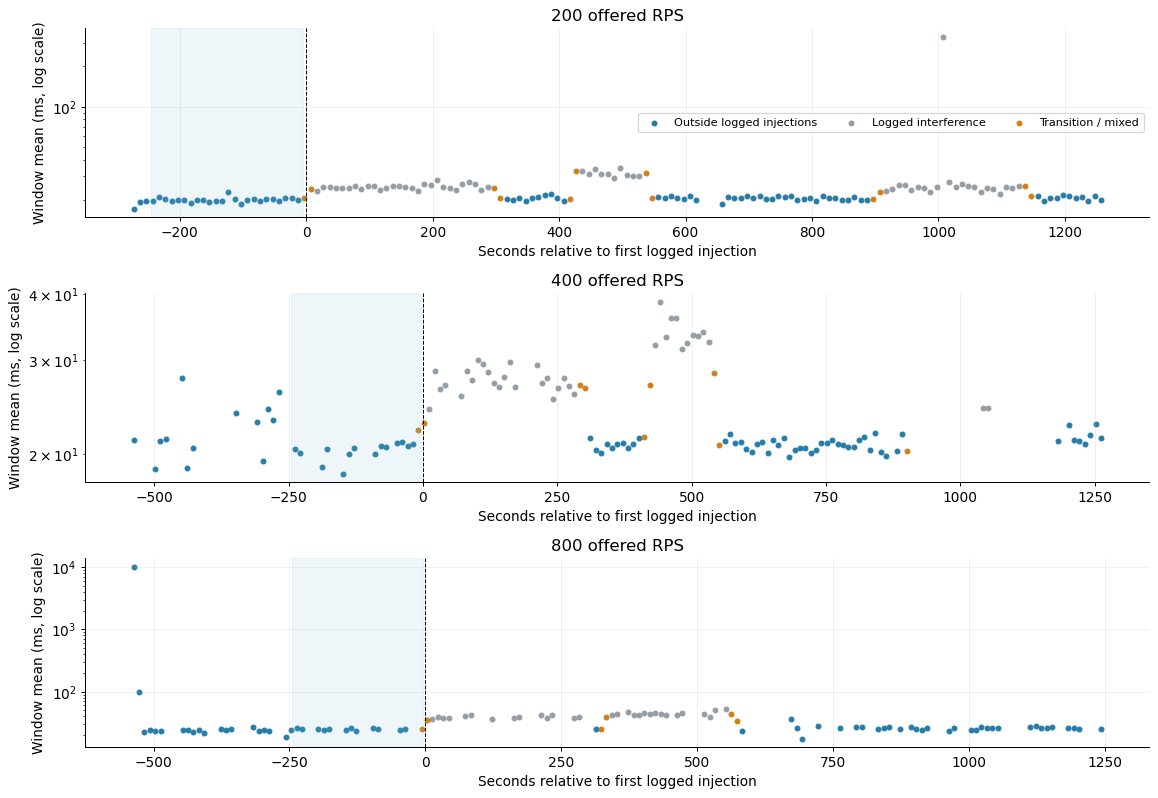

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(13,9), sharex=False)
for ax, load, a in zip(axes,[200,400,800],provenance["runs"]):
    rows = [z for z in windows if float(z["offered_rps"])==load]
    tt = np.array([float(z["window_start_seconds"])-a["first_injection_epoch_seconds"]+5 for z in rows])
    yy = np.array([float(z["mean_response_seconds"])*1000 for z in rows])
    phase = np.array([z["phase"] for z in rows])
    for mask, color, label in [(phase=="no_logged_interference", "#277da8", "Outside logged injections"),
        (np.char.startswith(phase,"interference:"), "#979da5", "Logged interference"),
        (np.isin(phase,["mixed_phase_window","transition_guard"]),"#d08018","Transition / mixed")]:
        ax.scatter(tt[mask],yy[mask],s=14,c=color,label=label)
    ax.axvspan(-245,-5,color="#75bbdd",alpha=.12)
    ax.axvline(0,color="black",lw=.8,ls="--")
    ax.set(yscale="log",title=f"{load} offered RPS", ylabel="Window mean (ms, log scale)", xlabel="Seconds relative to first logged injection")
axes[0].legend(ncol=3, fontsize=9)
finish("02_time_and_regime")

### Captured-request coverage in the baseline interval

Bars show counts of captured compose-graph-1 requests retained in each ten-second window. Empty bars mean no retained request in this selected graph, not zero offered workload. Sparse coverage is particularly important when interpreting a single run's fitted mean.

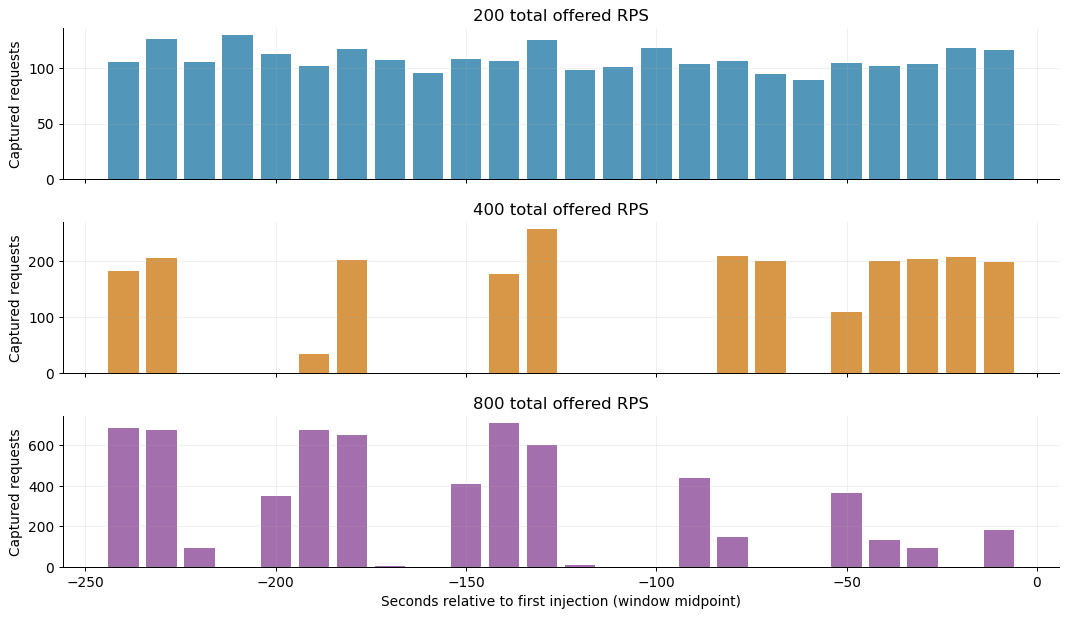

In [4]:
fig, axes=plt.subplots(3,1,figsize=(12,7),sharex=True)
for ax,load in zip(axes,[200,400,800]):
    k=x==load
    ax.bar(t[k],w[k],width=8,color=colors[load],alpha=.8)
    ax.set(title=f"{load} total offered RPS",ylabel="Captured requests")
axes[-1].set_xlabel("Seconds relative to first injection (window midpoint)")
finish("07_request_coverage")

## 3. Response distributions—not service-demand distributions

These are binned empirical distributions of root-span duration from all observed requests, separately outside and during logged injections. They are descriptive context only: neither distribution is used to fit the baseline. Injection schedules differ between runs, so the dashed curves do not represent one common controlled treatment. The plot zooms to 1–300 ms; out-of-range counts are printed below and remain in the denominator, rather than renormalizing away rare long responses.

800 RPS no_logged_interference: 0 below histogram range, 1 above 10,000 ms; retained in CDF denominator.


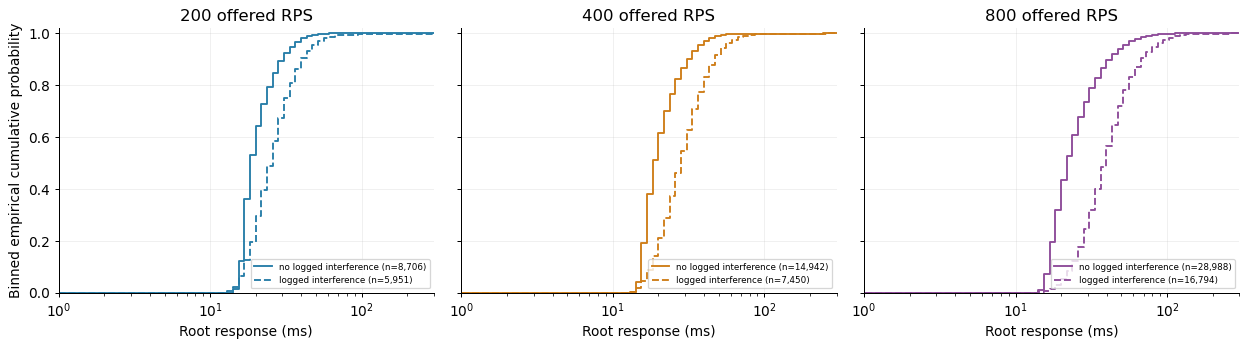

In [5]:
hist = records(DATA / "response_histograms.csv")
fig, axes = plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,load in zip(axes,[200,400,800]):
    for regime,style in [("no_logged_interference","-"),("logged_interference","--")]:
        rr=[z for z in hist if float(z["offered_rps"])==load and z["regime"]==regime]
        total=int(rr[0]["total_requests"]); below=int(rr[0]["below_range"]); above=int(rr[0]["above_range"])
        if below or above: print(f"{load} RPS {regime}: {below} below histogram range, {above} above 10,000 ms; retained in CDF denominator.")
        xx=np.array([float(z["right_ms"]) for z in rr]); cc=(below+np.cumsum([int(z["count"]) for z in rr]))/total
        ax.step(xx,cc,where="post",linestyle=style,color=colors[load],label=f"{regime.replace('_',' ')} (n={total:,})")
    ax.set(xscale="log",xlim=(1,300),ylim=(0,1.02),title=f"{load} offered RPS",xlabel="Root response (ms)")
    ax.legend(fontsize=7,loc="lower right")
axes[0].set_ylabel("Binned empirical cumulative probability")
finish("03_response_distributions")

## 4. A deliberately simple aggregate baseline

$$\widehat m(\lambda)=a+b\,\lambda/1000,\qquad a\geq0,\ b\geq0.$$

Here $\lambda$ is total offered RPS and $\widehat m$ is the conditional mean root response for compose graph 1. This is a **phenomenological affine curve**, not an M/M/1 formula or an identified service-time model. It assumes a nondecreasing approximately linear mean over the observed workload range and a common pre-injection regime across runs.

We minimize $\sum_{i\in\mathrm{train}}n_i(\bar R_i-\widehat m(\lambda_i))^2$ by bounded least squares. Request-count weighting gives captured requests equal weight; it does not imply independent observations or justify IID uncertainty intervals.

**Frozen split:** the first 120 seconds of the 240-second interval at 200 and 800 RPS are training data. Their later 120 seconds are temporal holdouts. **All 400-RPS windows are held out** for workload interpolation. No hyperparameters or alternative curve are chosen based on the 400-RPS results. Requests crossing a ten-second window edge are excluded in every split; this may disproportionately exclude very long responses. There is only one run per workload, not independent replicate runs. Empty windows contain no retained selected-graph requests and have no estimable mean; they are not filled with zeros. Counts below show coverage rather than implying all 72 windows are observed.

Fitted baseline: mean_seconds = 0.018222377 + 0.008127207 * offered_RPS/1000
Training-only constant comparator: 23.669 ms


|Split|Windows|Requests|Observed ms|Predicted ms|MAE ms|RMSE ms|Constant MAE ms|
|---|---|---|---|---|---|---|---|
|train|22|6178|23.669|23.669|0.456|0.611|1.728|
|heldout_time|19|2624|22.466|22.397|0.748|1.054|2.256|
|heldout_workload|13|2378|20.620|21.473|1.100|1.212|3.048|

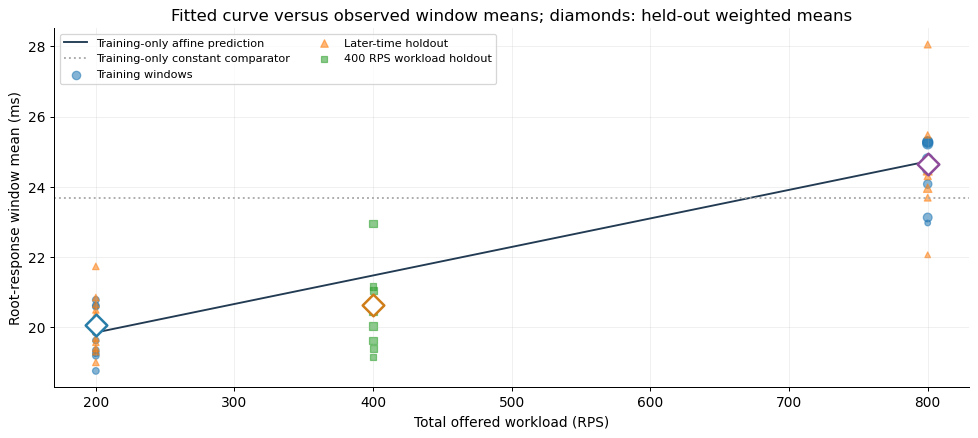

In [6]:
parameters=fit_affine(x[train],y[train],w[train])
prediction=predict_affine(parameters,x)
constant=np.average(y[train],weights=w[train])
print(f"Fitted baseline: mean_seconds = {parameters[0]:.9f} + {parameters[1]:.9f} * offered_RPS/1000")
print(f"Training-only constant comparator: {constant*1000:.3f} ms")
metrics=[]
for name in ["train","heldout_time","heldout_workload"]:
    k=split==name
    metrics.append(dict(split=name,windows=int(k.sum()),requests=int(w[k].sum()),
        observed_mean_ms=float(np.average(y[k],weights=w[k])*1000),
        predicted_mean_ms=float(np.average(prediction[k],weights=w[k])*1000),
        weighted_MAE_ms=float(np.average(abs(y[k]-prediction[k]),weights=w[k])*1000),
        weighted_RMSE_ms=float(np.sqrt(np.average((y[k]-prediction[k])**2,weights=w[k]))*1000),
        constant_MAE_ms=float(np.average(abs(y[k]-constant),weights=w[k])*1000)))
table(["Split","Windows","Requests","Observed ms","Predicted ms","MAE ms","RMSE ms","Constant MAE ms"],
      [(z["split"],z["windows"],z["requests"],*[f"{z[key]:.3f}" for key in
        ["observed_mean_ms","predicted_mean_ms","weighted_MAE_ms","weighted_RMSE_ms","constant_MAE_ms"]]) for z in metrics])
(PREVIEW/"baseline_metrics.json").write_text(json.dumps(dict(parameters_seconds=parameters.tolist(),metrics=metrics),indent=2)+"\n")
fig, ax=plt.subplots(figsize=(11,5))
grid=np.linspace(200,800,150)
ax.plot(grid,predict_affine(parameters,grid)*1000,color="#223b53",label="Training-only affine prediction")
ax.axhline(constant*1000,color="#aaa",ls=":",label="Training-only constant comparator")
styles={"train":("o","Training windows"),"heldout_time":("^","Later-time holdout"),"heldout_workload":("s","400 RPS workload holdout")}
for name,(marker,label) in styles.items():
    k=split==name
    ax.scatter(x[k],y[k]*1000,marker=marker,s=20+50*w[k]/w.max(),alpha=.55,label=label)
for load in [200,400,800]:
    k=(x==load)&(~train)
    ax.scatter([load],[np.average(y[k],weights=w[k])*1000],s=150,marker="D",facecolor="white",edgecolor=colors[load],lw=2,zorder=5)
ax.set(xlabel="Total offered workload (RPS)",ylabel="Root-response window mean (ms)",title="Fitted curve versus observed window means; diamonds: held-out weighted means")
ax.legend(fontsize=9,ncol=2)
finish("04_baseline_prediction")

## 5. Held-out errors and temporal structure

Residuals are **observed minus predicted ten-second means**, not per-request errors. Temporal holdout and held-out workload errors are reported separately. The smooth plotted line contains model evaluations, not additional experimental workload measurements. No behavior tolerance, confidence band or contract is inferred from these residuals.

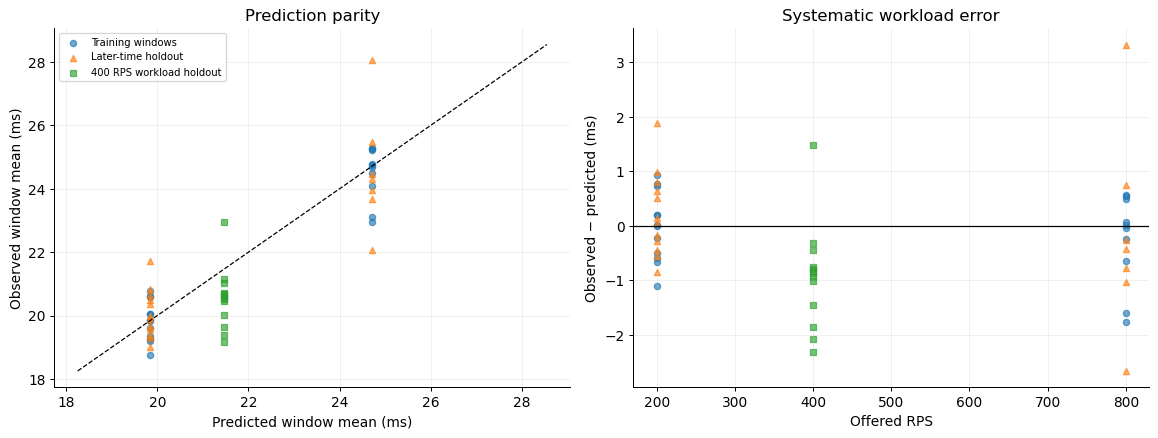

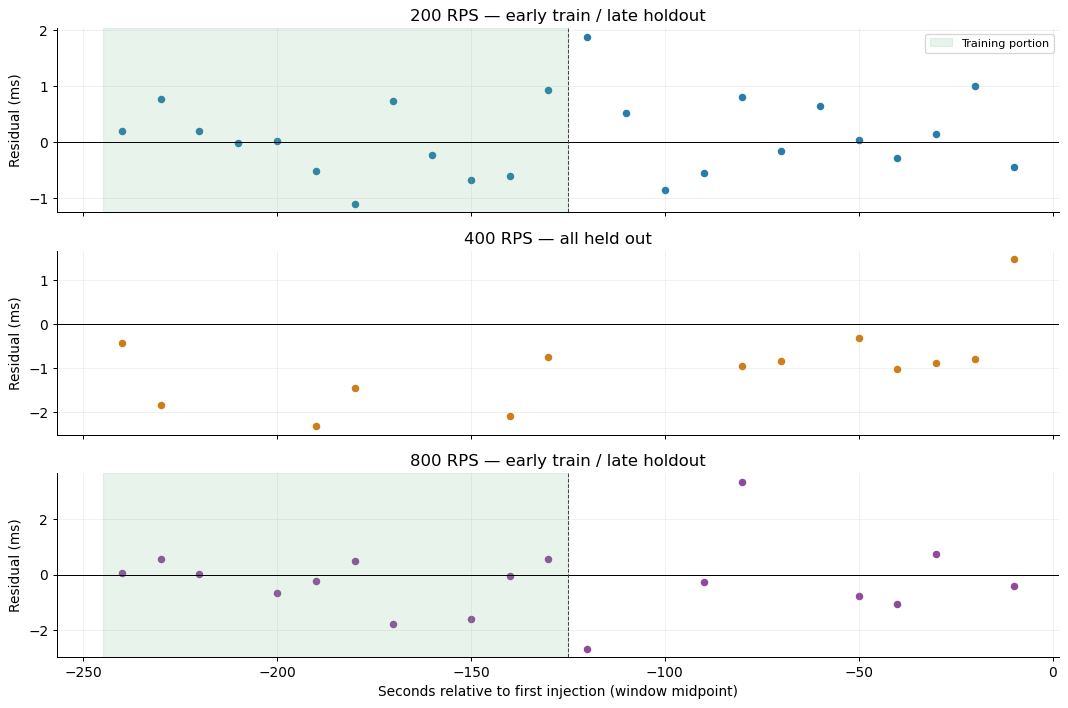

In [7]:
fig,(ax, bx)=plt.subplots(1,2,figsize=(13,5))
for name,(marker,label) in styles.items():
    k=split==name
    ax.scatter(prediction[k]*1000,y[k]*1000,marker=marker,s=25,alpha=.65,label=label)
    bx.scatter(x[k],(y[k]-prediction[k])*1000,marker=marker,s=25,alpha=.65,label=label)
limits=[min(y.min(),prediction.min())*1000-.5,max(y.max(),prediction.max())*1000+.5]
ax.plot(limits,limits,"k--",lw=1)
ax.set(xlabel="Predicted window mean (ms)",ylabel="Observed window mean (ms)",title="Prediction parity")
bx.axhline(0,color="black",lw=1)
bx.set(xlabel="Offered RPS",ylabel="Observed − predicted (ms)",title="Systematic workload error")
ax.legend(fontsize=8)
finish("05_prediction_errors")
fig,axes=plt.subplots(3,1,figsize=(12,8),sharex=True)
for ax,load in zip(axes,[200,400,800]):
    k=x==load
    ax.scatter(t[k],(y[k]-prediction[k])*1000,color=colors[load],s=25)
    ax.axhline(0,color="black",lw=.8)
    if load!=400:
        ax.axvspan(-245,-125,color="#74b88b",alpha=.16,label="Training portion")
        ax.axvline(-125,color="#444",ls="--",lw=.8)
    ax.set(title=f"{load} RPS — "+("all held out" if load==400 else "early train / late holdout"),ylabel="Residual (ms)")
axes[-1].set_xlabel("Seconds relative to first injection (window midpoint)")
axes[0].legend(fontsize=9)
finish("06_temporal_residuals")

## 6. What this baseline check establishes

- A cheap aggregate curve can be fitted without assuming intrinsic service demands or a queue discipline. Its interpolation error is directly visible at the independently held-out **workload**, not an independent replicate run.
- With only two training workload values, the affine fit is essentially determined by two weighted means. This does not validate the curve's shape, identify a saturation point, or support extrapolation beyond 200–800 RPS.
- Residual time structure and the 400-RPS mismatch motivate richer modeling; they are not proof that the graph-aware model will improve predictions.
- The imported graph supplies structural context for the next model. Server counts, service distributions, scheduling, RPC composition and a detailed likelihood still require explicit assumptions. No long inference has been started.

### Reproduce

From the repository root, install the repository requirements plus `requirements-notebook.txt`, then open this notebook or execute with `jupyter nbconvert --execute --to notebook --inplace examples/queueing/gamma_baseline.ipynb`.

The notebook runs from committed compact derived inputs without downloading raw traces. To regenerate those inputs from the pinned actual data:

```sh
python -m examples.queueing.gamma_study download --data-dir /path/to/gamma-small
python -m examples.queueing.gamma_baseline --data-dir /path/to/gamma-small \
  --output-dir examples/queueing/gamma/notebook_data
```

Provenance: [GAMMA dataset DOI](https://doi.org/10.34740/kaggle/dsv/7638732), [paper](https://www3.cs.stonybrook.edu/~anshul/www24_gamma.pdf), `gamma/sample_manifest.json` and `gamma/notebook_data/baseline_provenance.json`. Timestamp and duration units are established from the official exporter. Histograms are compact binned observations; no synthetic empirical points are added.